## ViT model 

### 01. Setup

In [1]:
import os
from pathlib import Path
import random
import copy

from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.optim as optim
from torchinfo import summary

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.dataset import create_dataloaders
from src.ViT_model_definitions import SmallViT

In [2]:
img_size = 64
batch_size = 32
lr = 0.001
epochs = 20 
#model_name = "ai_capstone_pytorch_state_dict.pth"
num_classes = 2 # number of classes in the dataset
models_dir =Path("models")
model_path = models_dir / "vit_pure.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device used is {device}")

Device used is cuda


In [3]:
train_loader, val_loader, test_loader = create_dataloaders(batch_size)

## 02. Create the ViT model

In [4]:
model = SmallViT().to(device)

In [5]:
summary(model)

Layer (type:depth-idx)                                       Param #
SmallViT                                                     4,096
├─PatchEmbedding: 1-1                                        --
│    └─Linear: 2-1                                           12,352
├─ModuleList: 1-2                                            --
│    └─TransformerBlock: 2-2                                 --
│    │    └─LayerNorm: 3-1                                   128
│    │    └─MultiheadAttention: 3-2                          16,640
│    │    └─Dropout: 3-3                                     --
│    │    └─LayerNorm: 3-4                                   128
│    │    └─Sequential: 3-5                                  8,320
│    └─TransformerBlock: 2-3                                 --
│    │    └─LayerNorm: 3-6                                   128
│    │    └─MultiheadAttention: 3-7                          16,640
│    │    └─Dropout: 3-8                                     --
│    │    └─La

### 03. Train the ViT model

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# History for plotting later
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}

# Best validation loss seen so far
best_val_loss = float("inf")

In [7]:
for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # =========================
    # Validation
    # =========================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total
    
    # =========================
    # Store history
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_accuracy)
    history["val_acc"].append(val_accuracy)

    # =========================
    # Save best model
    # =========================
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            model_path
        )

        saved = "  <-- saved"

    else:
        saved = ""
        
    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.3f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.3f}"
        f"{saved}"
    )

Epoch  1/20 | Train Loss: 0.1757 | Train Acc: 0.928 | Val Loss: 0.1313 | Val Acc: 0.947  <-- saved
Epoch  2/20 | Train Loss: 0.0557 | Train Acc: 0.977 | Val Loss: 0.0441 | Val Acc: 0.983  <-- saved
Epoch  3/20 | Train Loss: 0.0640 | Train Acc: 0.977 | Val Loss: 0.0660 | Val Acc: 0.972
Epoch  4/20 | Train Loss: 0.0320 | Train Acc: 0.987 | Val Loss: 0.0136 | Val Acc: 0.993  <-- saved
Epoch  5/20 | Train Loss: 0.0331 | Train Acc: 0.988 | Val Loss: 0.0296 | Val Acc: 0.989
Epoch  6/20 | Train Loss: 0.0351 | Train Acc: 0.986 | Val Loss: 0.0128 | Val Acc: 0.996  <-- saved
Epoch  7/20 | Train Loss: 0.0364 | Train Acc: 0.986 | Val Loss: 0.0482 | Val Acc: 0.978
Epoch  8/20 | Train Loss: 0.0274 | Train Acc: 0.990 | Val Loss: 0.0646 | Val Acc: 0.973
Epoch  9/20 | Train Loss: 0.0188 | Train Acc: 0.992 | Val Loss: 0.0147 | Val Acc: 0.992
Epoch 10/20 | Train Loss: 0.0222 | Train Acc: 0.993 | Val Loss: 0.0109 | Val Acc: 0.998  <-- saved
Epoch 11/20 | Train Loss: 0.0177 | Train Acc: 0.993 | Val Loss: 0

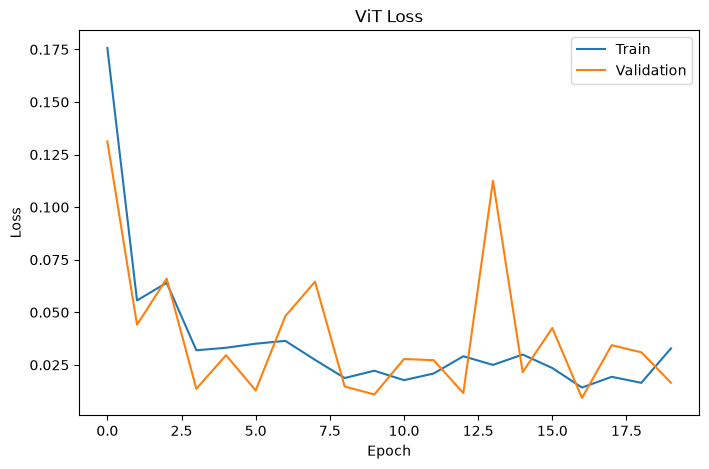

In [8]:
# =========================
# Plot Loss History
# =========================

plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("ViT Loss")

plt.show()

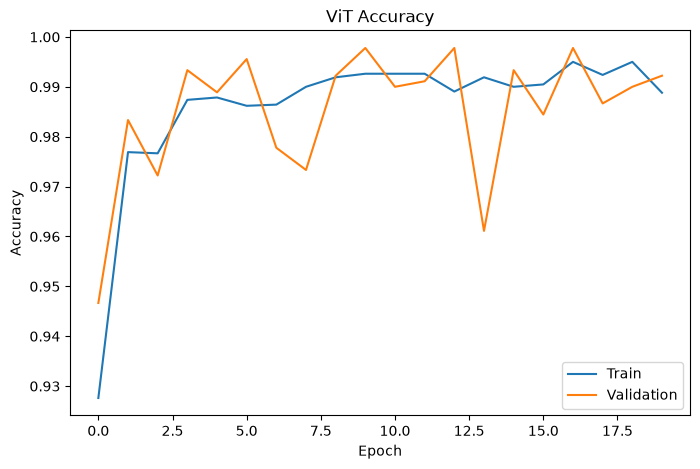

In [9]:
# =========================
# Plot Accuracy History
# =========================

plt.figure(figsize=(8, 5))

plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("ViT Accuracy")

plt.show()

### 04. Evaluate and show errors

In [11]:
model.load_state_dict(
    torch.load(model_path, weights_only=True)
)

model.eval()

correct = 0
total = 0

error_images = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        # Find misclassified images
        incorrect = predictions != labels

        for i in torch.where(incorrect)[0]:

            error_images.append({
                "image": images[i].cpu().clone(),
                "true_label": labels[i].item(),
                "predicted_label": predictions[i].item(),
                "predicted_probability": probabilities[
                    i, predictions[i]
                ].item(),
                "probabilities": probabilities[i].cpu().clone(),
            })

test_accuracy = correct / total

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Misclassified images: {len(error_images)}")

Test accuracy: 0.991
Misclassified images: 8


### Visualize the errors

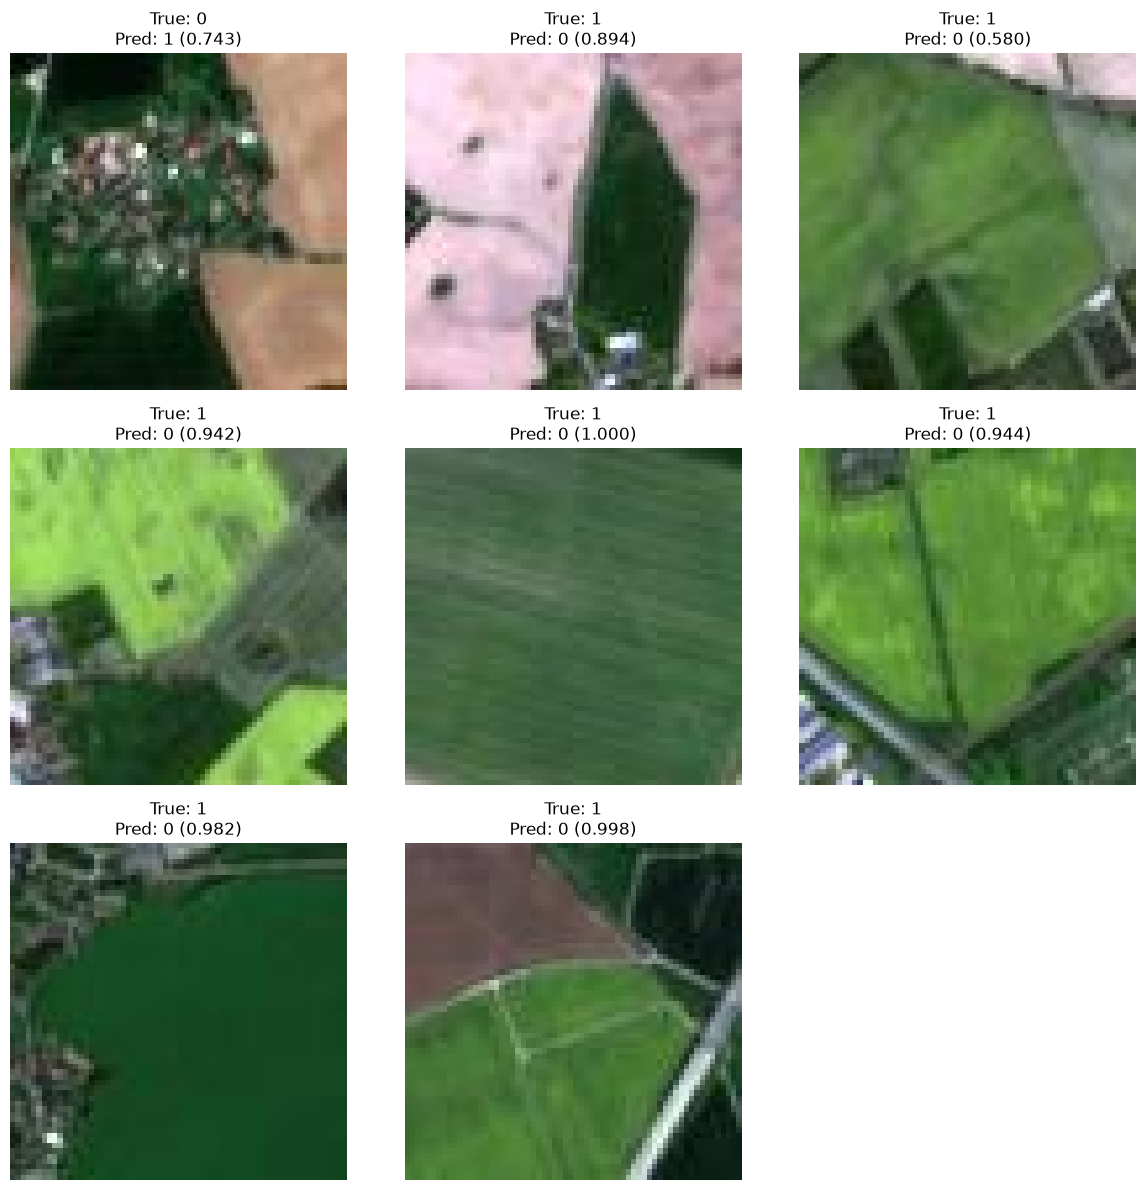

In [12]:
import matplotlib.pyplot as plt

n = min(len(error_images), 9)

plt.figure(figsize=(12, 12))

for i in range(n):

    item = error_images[i]

    image = item["image"]

    # Denormalize:
    # [-1, 1] -> [0, 1]
    image = image * 0.5 + 0.5

    # CHW -> HWC for matplotlib
    image = image.permute(1, 2, 0)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)

    true_name = item["true_label"]
    predicted_name = item["predicted_label"]
    probability = item["predicted_probability"]

    plt.title(
        f"True: {true_name}\n"
        f"Pred: {predicted_name} ({probability:.3f})"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()